# Diagnostics and comparison with OpenCV's Haar cascade

Exploratory analysis kept from development: feature inspection, alignment checks, separability of features and comparison against OpenCV's pretrained `haarcascade_frontalface_default.xml`. Cells keep their saved outputs; paths are relative to the repository root.

In [2]:
import cv2
import numpy as np
import pickle
import matplotlib.pyplot as plt

# Cargar las features generadas
with open('checkpoints/features.pkl', 'rb') as f:
    features = pickle.load(f)

# La feature seleccionada en ronda 1
clf_idx = 17377  # el idx que salió en tu log
x, y, w, h, ftype = features[clf_idx]
ftype_names = {0:'H-2rect', 1:'V-2rect', 2:'H-3rect', 3:'V-3rect', 4:'diag-4rect'}

print(f"Feature idx={clf_idx}")
print(f"  Posición: x={x}, y={y}, w={w}, h={h}")
print(f"  Tipo: {ftype} ({ftype_names[ftype]})")
print(f"  Cubre: {w*h} píxeles de una ventana 24x24")

# Visualizar sobre una ventana 24x24
canvas = np.ones((24, 24, 3), dtype=np.uint8) * 200
cv2.rectangle(canvas, (x, y), (x+w-1, y+h-1), (0,0,255), 1)

# Mostrar las dos mitades según el tipo
if ftype == 0:  # horizontal
    hw = w // 2
    cv2.rectangle(canvas, (x, y), (x+hw-1, y+h-1), (255,0,0), -1)
    cv2.rectangle(canvas, (x+hw, y), (x+w-1, y+h-1), (0,255,0), -1)
elif ftype == 1:  # vertical
    hh = h // 2
    cv2.rectangle(canvas, (x, y), (x+w-1, y+hh-1), (255,0,0), -1)
    cv2.rectangle(canvas, (x, y+hh), (x+w-1, y+h-1), (0,255,0), -1)

plt.figure(figsize=(4,4))
plt.imshow(canvas)
plt.title(f"Feature seleccionada (tipo={ftype_names[ftype]})\nx={x},y={y},w={w},h={h}")
plt.savefig('feature_debug.png')
print("Guardado en feature_debug.png")

# Además: ver distribución de valores de esa feature en caras vs no-caras
import os
PATH_FACES    = 'dataset/faces'
PATH_NONFACES = 'dataset/non_faces'

def integral_image(img):
    return np.cumsum(np.cumsum(img.astype(np.int32), axis=0), axis=1)

def sum_region(ii, x1, y1, x2, y2):
    A = ii[y2, x2]
    B = ii[y1-1, x2] if y1 > 0 else 0
    C = ii[y2, x1-1] if x1 > 0 else 0
    D = ii[y1-1, x1-1] if (x1>0 and y1>0) else 0
    return int(A - B - C + D)

def compute_feature(ii, x, y, w, h, ftype):
    if ftype == 0:
        hw = w//2
        return sum_region(ii,x,y,x+hw-1,y+h-1) - sum_region(ii,x+hw,y,x+w-1,y+h-1)
    elif ftype == 1:
        hh = h//2
        return sum_region(ii,x,y,x+w-1,y+hh-1) - sum_region(ii,x,y+hh,x+w-1,y+h-1)

vals_faces    = []
vals_nonfaces = []

for fname in os.listdir(PATH_FACES)[:500]:
    img = cv2.imread(os.path.join(PATH_FACES, fname), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        ii = integral_image(img)
        vals_faces.append(compute_feature(ii, x, y, w, h, ftype))

for fname in os.listdir(PATH_NONFACES)[:500]:
    img = cv2.imread(os.path.join(PATH_NONFACES, fname), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        ii = integral_image(img)
        vals_nonfaces.append(compute_feature(ii, x, y, w, h, ftype))

print(f"\nValores feature en CARAS:    mean={np.mean(vals_faces):.1f}  std={np.std(vals_faces):.1f}")
print(f"Valores feature en NO-CARAS: mean={np.mean(vals_nonfaces):.1f}  std={np.std(vals_nonfaces):.1f}")
print(f"Separación (|Δmean|/std_pooled): {abs(np.mean(vals_faces)-np.mean(vals_nonfaces)) / ((np.std(vals_faces)+np.std(vals_nonfaces))/2):.3f}")

IndexError: list index out of range

In [2]:
import numpy as np
import pickle
import cv2
import os

with open('checkpoints/features.pkl', 'rb') as f:
    features = pickle.load(f)

# Cargar una cara y computar la feature manualmente
PATH_FACES = 'dataset/faces'
fname = os.listdir(PATH_FACES)[0]
img = cv2.imread(os.path.join(PATH_FACES, fname), cv2.IMREAD_GRAYSCALE)

# Sin normalizar
ii_raw = np.cumsum(np.cumsum(img.astype(np.int32), axis=0), axis=1)

# Con normalizar
img_f = img.astype(np.float32)
mean, std = img_f.mean(), img_f.std()
img_f = (img_f - mean) / std
img_f = ((img_f + 3.0) * (255.0 / 6.0)).clip(0, 255).astype(np.int32)
ii_norm = np.cumsum(np.cumsum(img_f, axis=0), axis=1)

# Comparar en la feature idx=17377
x, y, w, h, ftype = features[5282]
print(f"Feature: x={x},y={y},w={w},h={h},ftype={ftype}")

def sum_region(ii, x1, y1, x2, y2):
    A = ii[y2, x2]
    B = ii[y1-1, x2] if y1 > 0 else 0
    C = ii[y2, x1-1] if x1 > 0 else 0
    D = ii[y1-1, x1-1] if (x1 > 0 and y1 > 0) else 0
    return int(A - B - C + D)


def compute_feature(ii, x, y, w, h, ftype=0):
    """
    ftype=0: Haar horizontal 2 rect  (izq − der)
    ftype=1: Haar vertical 2 rect    (arriba − abajo)
    ftype=2: Haar horizontal 3 rect  (izq − centro + der)
    ftype=3: Haar vertical 3 rect    (arriba − centro + abajo)
    ftype=4: Haar diagonal 4 rect    (topLeft − topRight − bottomLeft + bottomRight)
    """
    if ftype == 0:
        hw = w // 2
        return (sum_region(ii, x,    y, x+hw-1, y+h-1) -
                sum_region(ii, x+hw, y, x+w-1,  y+h-1))

    elif ftype == 1:
        hh = h // 2
        return (sum_region(ii, x, y,    x+w-1, y+hh-1) -
                sum_region(ii, x, y+hh, x+w-1, y+h-1))

    elif ftype == 2:
        tw = w // 3
        return (sum_region(ii, x,      y, x+tw-1,   y+h-1) -
                sum_region(ii, x+tw,   y, x+2*tw-1, y+h-1) +
                sum_region(ii, x+2*tw, y, x+w-1,    y+h-1))

    elif ftype == 3:
        th = h // 3
        return (sum_region(ii, x, y,      x+w-1, y+th-1)   -
                sum_region(ii, x, y+th,   x+w-1, y+2*th-1) +
                sum_region(ii, x, y+2*th, x+w-1, y+h-1))

    else:  # ftype == 4
        hw = w // 2
        hh = h // 2
        return (sum_region(ii, x,    y,    x+hw-1, y+hh-1) -
                sum_region(ii, x+hw, y,    x+w-1,  y+hh-1) -
                sum_region(ii, x,    y+hh, x+hw-1, y+h-1)  +
                sum_region(ii, x+hw, y+hh, x+w-1,  y+h-1))
    
    
val_raw  = compute_feature(ii_raw,  x, y, w, h, ftype)
val_norm = compute_feature(ii_norm, x, y, w, h, ftype)
print(f"Valor sin normalizar: {val_raw}")
print(f"Valor normalizado:    {val_norm}")

# Y lo más importante: ¿qué hay en el memmap para esa muestra?
import glob
mmap_files = glob.glob('checkpoints/stage_01_feats.dat')
if mmap_files:
    # necesitamos saber n_total y n_features para abrir el memmap
    print(f"\nMemmap existe: {mmap_files[0]}")
    print("Dime el n_total y n_features que usaste para poder abrirlo")

Feature: x=8,y=2,w=6,h=9,ftype=3
Valor sin normalizar: 3431
Valor normalizado:    3482

Memmap existe: checkpoints/stage_01_feats.dat
Dime el n_total y n_features que usaste para poder abrirlo


In [5]:
import pickle
import numpy as np
import glob

# Sacar dimensiones del checkpoint inprogress
ckpt_files = glob.glob('checkpoints/stage_01_inprogress.pkl')

class WeakClassifier:
    __slots__ = ('feature_index', 'threshold', 'polarity')

    def __init__(self, feature_index, threshold, polarity):
        self.feature_index = feature_index
        self.threshold     = threshold
        self.polarity      = polarity

    def predict(self, X):
        feat = np.array(X[:, self.feature_index], dtype=np.int64)
        return (self.polarity * feat < self.polarity * int(self.threshold)).astype(np.int32)
if ckpt_files:
    with open(ckpt_files[0], 'rb') as f:
        ckpt = pickle.load(f)
    print(f"mmap_shape: {ckpt['mmap_shape']}")
    n_total, n_features = ckpt['mmap_shape']
    n_pos = ckpt['n_pos']
else:
    # Si no hay inprogress, calcularlo del tamaño del archivo
    import os
    size = os.path.getsize('checkpoints/stage_01_feats.dat')
    print(f"Tamaño archivo: {size} bytes")
    with open('checkpoints/features.pkl', 'rb') as f:
        features = pickle.load(f)
    n_features = len(features)
    n_total = size // (n_features * 4)
    print(f"n_features={n_features}, n_total estimado={n_total}")

# Abrir memmap y ver qué hay realmente
mmap = np.memmap('checkpoints/stage_01_feats.dat', dtype=np.int32, mode='r', shape=(n_total, n_features))

print(f"\nShape memmap: {mmap.shape}")
print(f"n_pos={n_pos}")

# Estadísticas de la feature idx=17377 en caras vs no-caras
feat_idx = 5282
vals_pos = mmap[:n_pos, feat_idx]
vals_neg = mmap[n_pos:, feat_idx]

print(f"\nFeature {feat_idx} en memmap:")
print(f"  CARAS    - mean={vals_pos.mean():.1f}  std={vals_pos.std():.1f}  min={vals_pos.min()}  max={vals_pos.max()}")
print(f"  NO-CARAS - mean={vals_neg.mean():.1f}  std={vals_neg.std():.1f}  min={vals_neg.min()}  max={vals_neg.max()}")

# Lo más importante: ver si hay separación en CUALQUIER feature
# Buscar la feature con mayor separación real
print(f"\nBuscando las 5 features más separables en el memmap...")
separations = []
for i in range(0, n_features, 100):  # muestrear cada 100
    vp = mmap[:n_pos, i].astype(np.float64)
    vn = mmap[n_pos:, i].astype(np.float64)
    sep = abs(vp.mean() - vn.mean()) / (vp.std() + vn.std() + 1e-6)
    separations.append((sep, i))

separations.sort(reverse=True)
print(f"Top 5 features por separación de medias:")
for sep, idx in separations[:5]:
    x,y,w,h,ft = features[idx]
    print(f"  idx={idx} sep={sep:.4f} x={x},y={y},w={w},h={h},ftype={ft}")

mmap_shape: (1600, 12265)

Shape memmap: (1600, 12265)
n_pos=800

Feature 5282 en memmap:
  CARAS    - mean=2984.4  std=575.7  min=1222  max=4609
  NO-CARAS - mean=2326.5  std=567.7  min=70  max=4580

Buscando las 5 features más separables en el memmap...
Top 5 features por separación de medias:
  idx=5500 sep=0.3389 x=10,y=0,w=10,h=4,ftype=0
  idx=11800 sep=0.3383 x=4,y=8,w=12,h=14,ftype=1
  idx=900 sep=0.3256 x=2,y=10,w=22,h=10,ftype=1
  idx=0 sep=0.3067 x=8,y=10,w=14,h=12,ftype=1
  idx=11000 sep=0.3013 x=0,y=10,w=24,h=12,ftype=1


Guardado en face_alignment_debug.png

Media cara promedio: 130.8
Std cara promedio:   31.5  (alto = buena estructura, bajo = ruido)


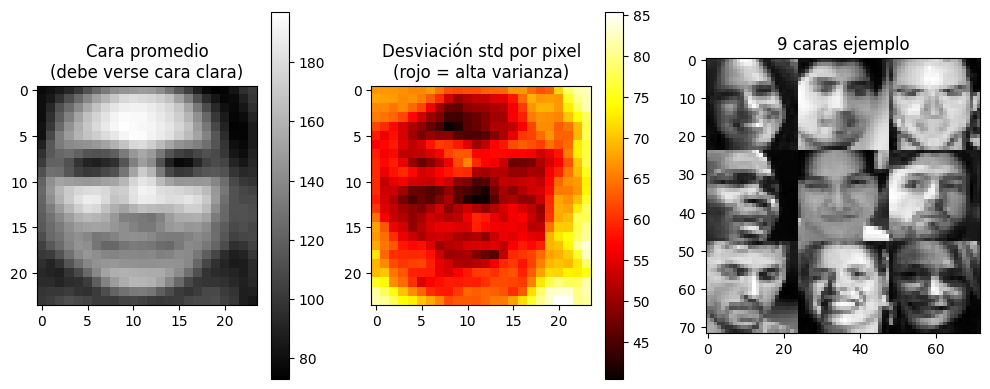

In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

PATH_FACES = 'dataset/faces_clean'

files = [f for f in os.listdir(PATH_FACES) if not f.startswith('.')][:100]
imgs = []
for f in files:
    img = cv2.imread(os.path.join(PATH_FACES, f), cv2.IMREAD_GRAYSCALE)
    if img is not None:
        imgs.append(img)

# Media de todas las caras — debería verse una cara promedio clara
mean_face = np.mean(imgs, axis=0).astype(np.uint8)

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(mean_face, cmap='gray')
plt.title('Cara promedio\n(debe verse cara clara)')
plt.colorbar()

# Std de todas las caras — zonas de alta varianza = mal alineadas
std_face = np.std(imgs, axis=0)
plt.subplot(1, 3, 2)
plt.imshow(std_face, cmap='hot')
plt.title('Desviación std por pixel\n(rojo = alta varianza)')
plt.colorbar()

# Mostrar 9 caras de ejemplo
plt.subplot(1, 3, 3)
grid = np.zeros((72, 72), dtype=np.uint8)
for i in range(9):
    r, c = divmod(i, 3)
    grid[r*24:(r+1)*24, c*24:(c+1)*24] = imgs[i]
plt.imshow(grid, cmap='gray')
plt.title('9 caras ejemplo')

plt.tight_layout()
plt.savefig('face_alignment_debug.png', dpi=150)
print("Guardado en face_alignment_debug.png")
print(f"\nMedia cara promedio: {mean_face.mean():.1f}")
print(f"Std cara promedio:   {mean_face.std():.1f}  (alto = buena estructura, bajo = ruido)")

Total caras:       20000
Detectadas por VJ: 561  (2.8%)
No detectadas:     19439  (97.2%)
Guardado en caras_no_detectadas.png


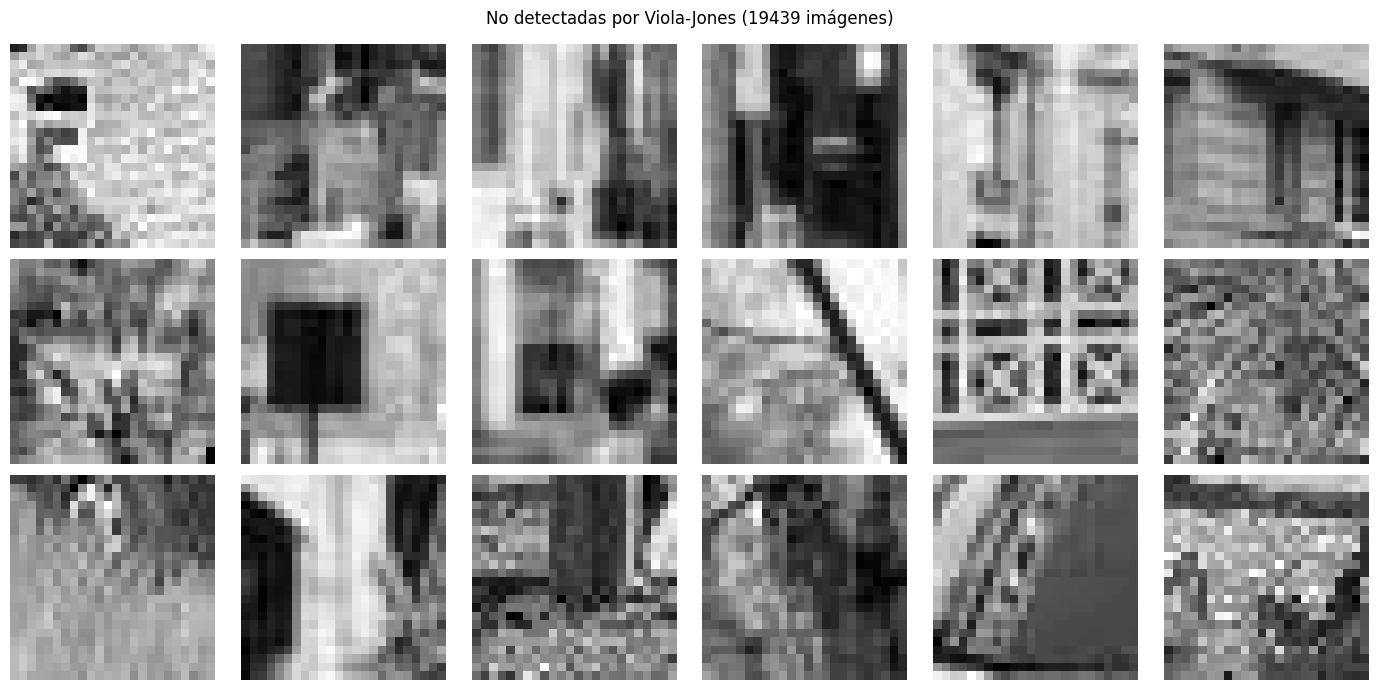

In [ ]:
import cv2
import os
import numpy as np

PATH_FACES = 'face_images'
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)
if face_cascade.empty():
    print("¡Error! No se pudo cargar el archivo XML del clasificador.")


files = [f for f in os.listdir(PATH_FACES) if not f.startswith('.')]
detected     = []
not_detected = []

for fname in files:
    img = cv2.imread(os.path.join(PATH_FACES, fname), cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
    # Escalar a tamaño razonable para el detector si es muy pequeño
    faces = face_cascade.detectMultiScale(
        img,
        scaleFactor=1.1,
        minNeighbors=1,
        minSize=(20, 20)
    )
    if len(faces) > 0:
        detected.append(fname)
    else:
        not_detected.append(fname)

print(f"Total caras:       {len(files)}")
print(f"Detectadas por VJ: {len(detected)}  ({100*len(detected)/len(files):.1f}%)")
print(f"No detectadas:     {len(not_detected)}  ({100*len(not_detected)/len(files):.1f}%)")

# Guardar ejemplos de no detectadas para verlas
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
fig.suptitle(f'No detectadas por Viola-Jones ({len(not_detected)} imágenes)', fontsize=12)
for ax, fname in zip(axes.flat, detected[:18]):
    img = cv2.imread(os.path.join(PATH_FACES, fname), cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap='gray')
    ax.axis('off')
for ax in axes.flat[len(not_detected[:18]):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig('caras_no_detectadas.png', dpi=150)
print("Guardado en caras_no_detectadas.png")

In [ ]:
import numpy as np
import pickle

with open('checkpoints_feature3/features.pkl', 'rb') as f:
    features = pickle.load(f)

mmap = np.memmap('checkpoints_feature3/stage_01_feats.dat', 
                  dtype=np.int32, mode='r', shape=(1600, 12265))

n_pos = 800
vals_pos = mmap[:n_pos].astype(np.float32)
vals_neg = mmap[n_pos:].astype(np.float32)

mean_pos = vals_pos.mean(axis=0)
mean_neg = vals_neg.mean(axis=0)
std_pos  = vals_pos.std(axis=0)
std_neg  = vals_neg.std(axis=0)

# Separación real sobre TODAS las features
sep = np.abs(mean_pos - mean_neg) / (std_pos + std_neg + 1e-6)

top_idx = np.argsort(sep)[::-1][:10]
print("Top 10 features más separables (todas, no muestreadas):")
for idx in top_idx:
    x,y,w,h,ft = features[idx]
    print(f"  idx={idx:6d} | sep={sep[idx]:.4f} | x={x:2d},y={y:2d},w={w:2d},h={h:2d} | ftype={ft}")

print(f"\nSeparación máxima posible: {sep.max():.4f}")
print(f"Separación mediana:        {np.median(sep):.4f}")
print(f"Features con sep > 0.5:    {(sep > 0.5).sum()}")
print(f"Features con sep > 0.3:    {(sep > 0.3).sum()}")

Top 10 features más separables (todas, no muestreadas):
  idx= 10619 | sep=0.5769 | x= 6,y= 2,w=10,h= 9 | ftype=3
  idx=  5282 | sep=0.5754 | x= 8,y= 2,w= 6,h= 9 | ftype=3
  idx=  6716 | sep=0.5751 | x= 8,y= 2,w= 8,h= 9 | ftype=3
  idx=  3425 | sep=0.5616 | x=10,y= 2,w= 4,h= 9 | ftype=3
  idx=  6608 | sep=0.5615 | x= 6,y= 2,w=12,h= 9 | ftype=3
  idx= 12077 | sep=0.5615 | x= 4,y= 2,w=12,h= 9 | ftype=3
  idx=  5175 | sep=0.5605 | x= 4,y= 2,w=14,h= 9 | ftype=3
  idx=  9794 | sep=0.5601 | x= 6,y= 2,w= 8,h= 9 | ftype=3
  idx=   541 | sep=0.5417 | x=10,y= 2,w= 6,h= 9 | ftype=3
  idx=  2233 | sep=0.5413 | x= 8,y= 2,w=10,h= 9 | ftype=3

Separación máxima posible: 0.5769
Separación mediana:        0.1076
Features con sep > 0.5:    17
Features con sep > 0.3:    511


In [8]:
import numpy as np

mmap = np.memmap('checkpoints/stage_01_feats.dat',
                  dtype=np.int32, mode='r', shape=(1600, 12265))

n_pos = 800
y_true = np.array([1]*n_pos + [0]*(1600-n_pos), dtype=np.int32)
w = np.ones(1600, dtype=np.float64) / 1600

col = mmap[:, 5282].astype(np.float64)

print(f"mean caras:    {col[:n_pos].mean():.1f}")
print(f"mean no-caras: {col[n_pos:].mean():.1f}")

# Probar umbral en la mediana de separación
thr = (col[:n_pos].mean() + col[n_pos:].mean()) / 2

for pol in [1, -1]:
    preds = (pol * col < pol * thr).astype(np.int32)
    err = float(np.sum(w * (preds != y_true)))
    tp = np.sum((preds==1) & (y_true==1))
    fp = np.sum((preds==1) & (y_true==0))
    print(f"pol={pol:+d} | err={err:.4f} | TP={tp} FP={fp}")

mean caras:    2984.4
mean no-caras: 2326.5
pol=+1 | err=0.7112 | TP=231 FP=569
pol=-1 | err=0.2888 | TP=569 FP=231


Total features: 2913
Total stages: 25

Features por stage (primeros 10):
  Stage  1:   9 features
  Stage  2:  16 features
  Stage  3:  27 features
  Stage  4:  32 features
  Stage  5:  52 features
  Stage  6:  53 features
  Stage  7:  62 features
  Stage  8:  72 features
  Stage  9:  83 features
  Stage 10:  91 features

Detalle 1ª feature de los 5 primeros stages:

  Stage 1 — feature idx=0 (2 rects):
    x=6 y=4 w=12 h=9 weight=-1.00
    x=6 y=7 w=12 h=3 weight=+3.00

  Stage 2 — feature idx=9 (2 rects):
    x=6 y=6 w=12 h=6 weight=-1.00
    x=6 y=8 w=12 h=2 weight=+3.00

  Stage 3 — feature idx=25 (2 rects):
    x=0 y=3 w=24 h=3 weight=-1.00
    x=8 y=3 w=8 h=3 weight=+3.00

  Stage 4 — feature idx=52 (2 rects):
    x=6 y=4 w=12 h=9 weight=-1.00
    x=6 y=7 w=12 h=3 weight=+3.00

  Stage 5 — feature idx=84 (2 rects):
    x=6 y=0 w=12 h=9 weight=-1.00
    x=6 y=3 w=12 h=3 weight=+3.00


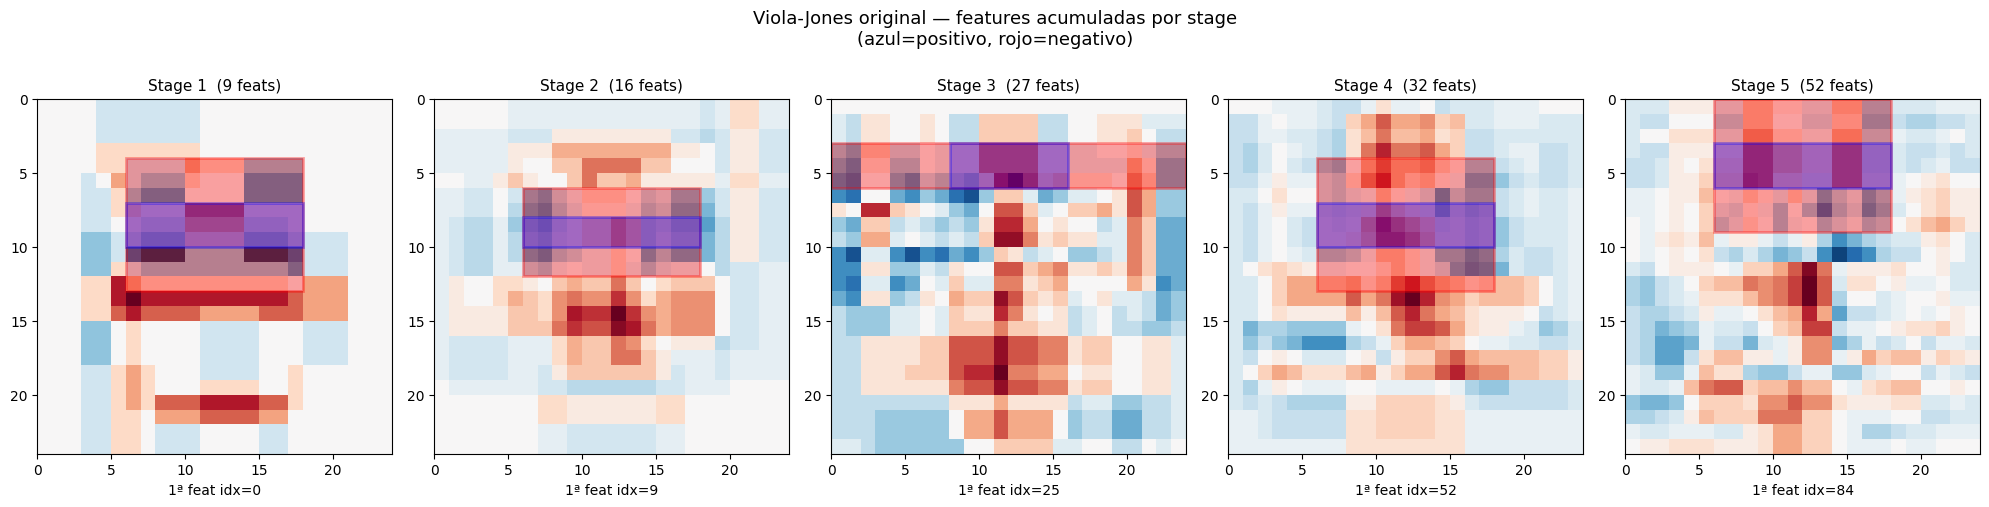


Guardado en viola_jones_stages.png


In [1]:
import xml.etree.ElementTree as ET
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

xml_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
tree = ET.parse(xml_path)
root = tree.getroot()
cascade_node = root.find('cascade')

# ── Parsear features ──────────────────────────────────────────
features_node = cascade_node.find('features')
all_features = []
for feat in features_node:
    rects = []
    rects_node = feat.find('rects')
    for r in rects_node:
        vals = list(map(float, r.text.strip().split()))
        rects.append(vals)  # x y w h weight
    all_features.append(rects)

print(f"Total features: {len(all_features)}")

# ── Parsear stages ────────────────────────────────────────────
stages_node = cascade_node.find('stages')
stages = []
for stage in stages_node:
    threshold = float(stage.find('stageThreshold').text)
    weak_clfs = []
    for wc in stage.find('weakClassifiers'):
        # cada <_> tiene <internalNodes> y <leafValues>
        internal = wc.find('internalNodes').text.strip().split()
        # formato: left_val right_val feature_idx threshold
        feat_idx = int(internal[2])
        weak_clfs.append(feat_idx)
    stages.append({
        'threshold':       threshold,
        'n_features':      len(weak_clfs),
        'feature_indices': weak_clfs,
    })

print(f"Total stages: {len(stages)}")
print(f"\nFeatures por stage (primeros 10):")
for i, s in enumerate(stages[:10]):
    print(f"  Stage {i+1:2d}: {s['n_features']:3d} features")

# ── Detalle de la 1ª feature de cada stage ───────────────────
print("\nDetalle 1ª feature de los 5 primeros stages:")
for i in range(5):
    idx = stages[i]['feature_indices'][0]
    rects = all_features[idx]
    print(f"\n  Stage {i+1} — feature idx={idx} ({len(rects)} rects):")
    for r in rects:
        print(f"    x={r[0]:.0f} y={r[1]:.0f} w={r[2]:.0f} h={r[3]:.0f} weight={r[4]:+.2f}")

# ── Visualizar las 5 primeras stages ─────────────────────────
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle('Viola-Jones original — features acumuladas por stage\n(azul=positivo, rojo=negativo)', fontsize=13)

WINDOW_SIZE = 24

for stage_idx in range(5):
    ax = axes[stage_idx]
    ax.set_xlim(0, WINDOW_SIZE)
    ax.set_ylim(WINDOW_SIZE, 0)
    ax.set_aspect('equal')
    ax.set_title(f'Stage {stage_idx+1}  ({stages[stage_idx]["n_features"]} feats)', fontsize=11)
    ax.set_facecolor('#e8e8e8')

    activation = np.zeros((WINDOW_SIZE, WINDOW_SIZE), dtype=np.float32)

    for feat_idx in stages[stage_idx]['feature_indices']:
        for rect in all_features[feat_idx]:
            x, y, w, h, weight = int(rect[0]), int(rect[1]), int(rect[2]), int(rect[3]), rect[4]
            activation[y:y+h, x:x+w] += weight

    vmax = max(abs(activation.min()), abs(activation.max()), 1e-6)
    ax.imshow(activation, cmap='RdBu_r', vmin=-vmax, vmax=vmax,
              extent=[0, WINDOW_SIZE, WINDOW_SIZE, 0])

    # Dibujar rectángulos de la 1ª feature encima
    first_idx = stages[stage_idx]['feature_indices'][0]
    for rect in all_features[first_idx]:
        x, y, w, h, weight = int(rect[0]), int(rect[1]), int(rect[2]), int(rect[3]), rect[4]
        color = 'blue' if weight > 0 else 'red'
        ax.add_patch(patches.Rectangle((x, y), w, h,
                     linewidth=2, edgecolor=color,
                     facecolor=color, alpha=0.35))

    ax.set_xlabel(f'1ª feat idx={stages[stage_idx]["feature_indices"][0]}')

plt.tight_layout()
plt.savefig('viola_jones_stages.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nGuardado en viola_jones_stages.png")

### Features 'Mínimas' por tipo (las más eficientes) ###

Tipo: 2 rectángulos (Encontrada en Stage 0)
  Índice original: 0
    Rect 0: x=6.0, y=4.0, w=12.0, h=9.0, weight=-1.0
    Rect 1: x=6.0, y=7.0, w=12.0, h=3.0, weight=3.0

Tipo: 3 rectángulos (Encontrada en Stage 2)
  Índice original: 35
    Rect 0: x=5.0, y=6.0, w=14.0, h=12.0, weight=-1.0
    Rect 1: x=5.0, y=6.0, w=7.0, h=6.0, weight=2.0
    Rect 2: x=12.0, y=12.0, w=7.0, h=6.0, weight=2.0


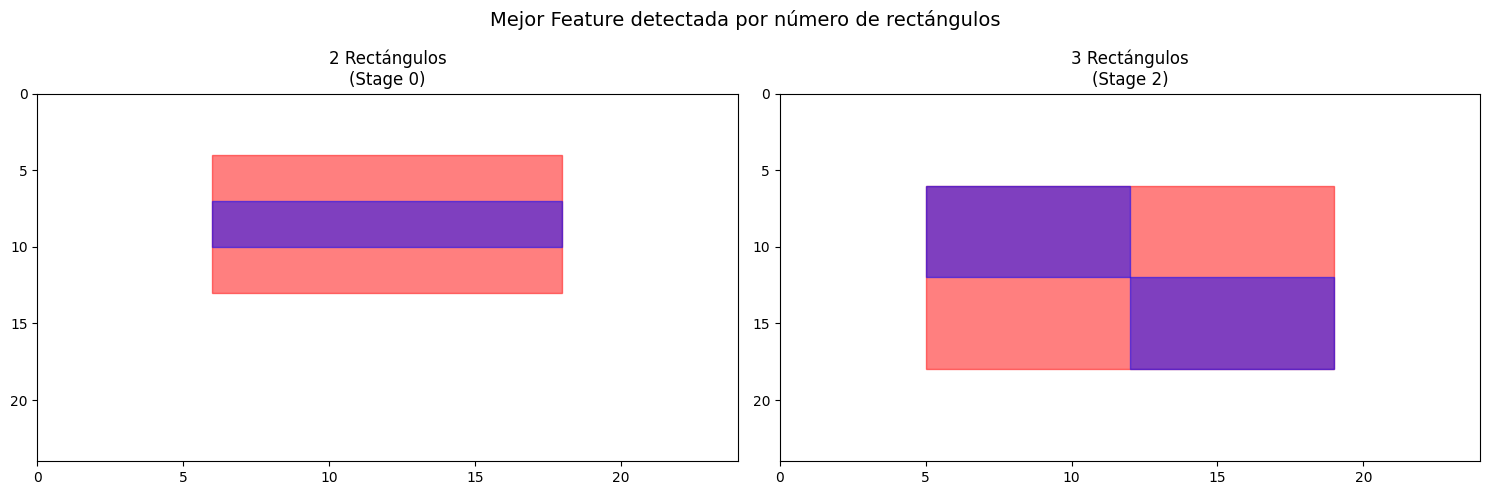

In [2]:
# --- Clasificación por tipo de feature ---
# 2 rects: Bordes o gradientes simples
# 3 rects: Líneas (como el puente de la nariz)
# 4 rects: Diagonales o texturas complejas

def classify_features_by_type(stages, all_features):
    best_by_type = {}
    
    for s_idx, stage in enumerate(stages):
        for f_idx in stage['feature_indices']:
            rects = all_features[f_idx]
            n_rects = len(rects)
            
            # Si es la primera vez que vemos este tipo (n_rects), 
            # la guardamos porque es la más "temprana" (más eficiente)
            if n_rects not in best_by_type:
                best_by_type[n_rects] = {
                    'stage': s_idx,
                    'feature_idx': f_idx,
                    'rects': rects
                }
    return best_by_type

min_features = classify_features_by_type(stages, all_features)

print("### Features 'Mínimas' por tipo (las más eficientes) ###")
for n_rects, data in sorted(min_features.items()):
    print(f"\nTipo: {n_rects} rectángulos (Encontrada en Stage {data['stage']})")
    print(f"  Índice original: {data['feature_idx']}")
    for i, r in enumerate(data['rects']):
        print(f"    Rect {i}: x={r[0]}, y={r[1]}, w={r[2]}, h={r[3]}, weight={r[4]}")

# --- Visualización de las 'Top Features' por tipo ---
fig, axes = plt.subplots(1, len(min_features), figsize=(15, 5))
fig.suptitle('Mejor Feature detectada por número de rectángulos', fontsize=14)

for i, (n_rects, data) in enumerate(sorted(min_features.items())):
    ax = axes[i]
    ax.set_xlim(0, 24); ax.set_ylim(24, 0)
    ax.set_title(f"{n_rects} Rectángulos\n(Stage {data['stage']})")
    
    for r in data['rects']:
        x, y, w, h, weight = r
        color = 'blue' if weight > 0 else 'red'
        ax.add_patch(patches.Rectangle((x, y), w, h, color=color, alpha=0.5))
        
plt.tight_layout()
plt.show()

In [11]:
import xml.etree.ElementTree as ET
import cv2

xml_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
tree = ET.parse(xml_path)
root = tree.getroot()
cascade_node = root.find('cascade')

# Ver todos los hijos directos del cascade
print("Hijos directos de <cascade>:")
for child in cascade_node:
    print(f"  <{child.tag}>  hijos={len(list(child))}")

# Ver estructura del primer stage
print("\nEstructura del primer stage:")
stages_node = cascade_node.find('stages')
first_stage = list(stages_node)[0]
for child in first_stage:
    print(f"  <{child.tag}> = '{child.text.strip() if child.text else ''}' | hijos={len(list(child))}")
    for grandchild in list(child)[:2]:
        print(f"    <{grandchild.tag}> = '{grandchild.text.strip() if grandchild.text else ''}' | hijos={len(list(grandchild))}")

Hijos directos de <cascade>:
  <stageType>  hijos=0
  <featureType>  hijos=0
  <height>  hijos=0
  <width>  hijos=0
  <stageParams>  hijos=1
  <featureParams>  hijos=1
  <stageNum>  hijos=0
  <stages>  hijos=25
  <features>  hijos=2913

Estructura del primer stage:
  <maxWeakCount> = '9' | hijos=0
  <stageThreshold> = '-5.0425500869750977e+00' | hijos=0
  <weakClassifiers> = '' | hijos=9
    <_> = '' | hijos=2
    <_> = '' | hijos=2


In [2]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
class WeakClassifier:
    __slots__ = ('feature_index', 'threshold', 'polarity')

    def __init__(self, feature_index, threshold, polarity):
        self.feature_index = feature_index
        self.threshold     = threshold
        self.polarity      = polarity

    def predict(self, X):
        feat = np.array(X[:, self.feature_index], dtype=np.int64)
        return (self.polarity * feat < self.polarity * int(self.threshold)).astype(np.int32)
# ── Cargar datos ──────────────────────────────────────────────
# with open('checkpoints_last/features.pkl', 'rb') as f:
#     features = pickle.load(f)

stages = []
for i in range(1, 2):
    path = f'checkpoints_feature3/stage_{i:02d}_complete.pkl'
    with open(path, 'rb') as f:
        s = pickle.load(f)
    stages.append(s)
    print(f"Stage {i}: {len(s['classifiers'])} clasificadores | θ={s['theta']:.4f}")

# ── Visualizar ────────────────────────────────────────────────
WINDOW_SIZE = 24
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle('Tu cascada — features acumuladas por stage\n(azul=positivo, rojo=negativo)', fontsize=13)

ftype_names = {0:'H-2rect', 1:'V-2rect', 2:'H-3rect', 3:'V-3rect', 4:'diag-4rect'}

for stage_idx, (ax, stage) in enumerate(zip(axes, stages)):
    clfs      = stage['classifiers']
    alphas    = stage['alphas']
    feat_list = stage['features_global']

    ax.set_xlim(0, WINDOW_SIZE)
    ax.set_ylim(WINDOW_SIZE, 0)
    ax.set_aspect('equal')
    ax.set_facecolor('#e8e8e8')
    ax.set_title(f'Stage {stage_idx+1}  ({len(clfs)} feats)\nθ={stage["theta"]:.3f}', fontsize=11)

    # Mapa de activación ponderado por alpha
    activation = np.zeros((WINDOW_SIZE, WINDOW_SIZE), dtype=np.float32)

    for clf, alpha in zip(clfs, alphas):
        x, y, w, h, ftype = feat_list[clf.feature_index]
        x, y, w, h = int(x), int(y), int(w), int(h)
        sign = clf.polarity  # +1 o -1 indica qué región es "cara"

        if ftype == 0:   # H-2rect: izq positivo, der negativo
            hw = w // 2
            activation[y:y+h, x:x+hw]    += alpha * sign
            activation[y:y+h, x+hw:x+w]  -= alpha * sign
        elif ftype == 1: # V-2rect: arriba positivo, abajo negativo
            hh = h // 2
            activation[y:y+hh,  x:x+w]   += alpha * sign
            activation[y+hh:y+h, x:x+w]  -= alpha * sign
        elif ftype == 2: # H-3rect: izq+der positivo, centro negativo
            tw = w // 3
            activation[y:y+h, x:x+tw]         += alpha * sign
            activation[y:y+h, x+tw:x+2*tw]    -= alpha * sign
            activation[y:y+h, x+2*tw:x+w]     += alpha * sign
        elif ftype == 3: # V-3rect: arriba+abajo positivo, centro negativo
            th = h // 3
            activation[y:y+th,     x:x+w]     += alpha * sign
            activation[y+th:y+2*th, x:x+w]    -= alpha * sign
            activation[y+2*th:y+h,  x:x+w]    += alpha * sign
        elif ftype == 4: # diag-4rect
            hw, hh = w // 2, h // 2
            activation[y:y+hh,    x:x+hw]     += alpha * sign
            activation[y:y+hh,    x+hw:x+w]   -= alpha * sign
            activation[y+hh:y+h,  x:x+hw]     -= alpha * sign
            activation[y+hh:y+h,  x+hw:x+w]   += alpha * sign

    vmax = max(abs(activation.min()), abs(activation.max()), 1e-6)
    ax.imshow(activation, cmap='RdBu_r', vmin=-vmax, vmax=vmax,
              extent=[0, WINDOW_SIZE, WINDOW_SIZE, 0])

    # Dibujar rectángulos del clasificador con mayor alpha
    best_clf   = clfs[int(np.argmax(alphas))]
    best_alpha = max(alphas)
    x, y, w, h, ftype = feat_list[best_clf.feature_index]
    x, y, w, h = int(x), int(y), int(w), int(h)

    colors = {0:('blue','green'), 1:('blue','green'),
              2:('blue','green','blue'), 3:('blue','green','blue'),
              4:('blue','green','green','blue')}

    if ftype == 0:
        hw = w//2
        for rx,rw,c in [(x,hw,'blue'),(x+hw,hw,'red')]:
            ax.add_patch(patches.Rectangle((rx,y),rw,h,
                         linewidth=2,edgecolor=c,facecolor=c,alpha=0.4))
    elif ftype == 1:
        hh = h//2
        for ry,rh,c in [(y,hh,'blue'),(y+hh,hh,'red')]:
            ax.add_patch(patches.Rectangle((x,ry),w,rh,
                         linewidth=2,edgecolor=c,facecolor=c,alpha=0.4))
    elif ftype == 2:
        tw = w//3
        for rx,c in [(x,'blue'),(x+tw,'red'),(x+2*tw,'blue')]:
            ax.add_patch(patches.Rectangle((rx,y),tw,h,
                         linewidth=2,edgecolor=c,facecolor=c,alpha=0.4))
    elif ftype == 3:
        th = h//3
        for ry,c in [(y,'blue'),(y+th,'red'),(y+2*th,'blue')]:
            ax.add_patch(patches.Rectangle((x,ry),w,th,
                         linewidth=2,edgecolor=c,facecolor=c,alpha=0.4))
    elif ftype == 4:
        hw,hh = w//2,h//2
        for rx,ry,c in [(x,y,'blue'),(x+hw,y,'red'),(x,y+hh,'red'),(x+hw,y+hh,'blue')]:
            ax.add_patch(patches.Rectangle((rx,ry),hw,hh,
                         linewidth=2,edgecolor=c,facecolor=c,alpha=0.4))

    ax.set_xlabel(f'mejor clf: α={best_alpha:.3f} | {ftype_names[ftype]}\n'
                  f'x={x},y={y},w={w},h={h}', fontsize=8)

plt.tight_layout()
plt.savefig('mi_cascada_stages.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado en mi_cascada_stages.png")

FileNotFoundError: [Errno 2] No such file or directory: 'checkpoints_feature3/stage_01_complete.pkl'

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

CHECKPOINT_DIR = "checkpoints_total"
NUMBER_STAGES = 1

class WeakClassifier:
    __slots__ = ('feature_index', 'threshold', 'polarity')

    def __init__(self, feature_index, threshold, polarity):
        self.feature_index = feature_index
        self.threshold     = threshold
        self.polarity      = polarity

    def predict(self, X):
        feat = np.array(X[:, self.feature_index], dtype=np.int64)
        return (self.polarity * feat < self.polarity * int(self.threshold)).astype(np.int32)

# ── Cargar datos ──────────────────────────────────────────────
# with open(f'{CHECKPOINT_DIR}/features.pkl', 'rb') as f:
#     features = pickle.load(f)

stages = []
for i in range(1, NUMBER_STAGES+1):
    path = f'{CHECKPOINT_DIR}/stage_{i:02d}_complete.pkl'
    with open(path, 'rb') as f:
        s = pickle.load(f)
    stages.append(s)
    print(f"Stage {i}: {len(s['classifiers'])} clasificadores | θ={s['theta']:.4f}")

# ── Configuración ─────────────────────────────────────────────
WINDOW_SIZE = 24
FTYPE_NAMES = {
    0: 'H-2rect\n(izq/der)',
    1: 'V-2rect\n(arr/abj)',
    2: 'H-3rect\n(izq|cen|der)',
    3: 'V-3rect\n(arr|cen|abj)',
    4: 'Diagonal\n(4rect)',
}
N_FTYPES = 5

def compute_activation_for_ftype(clfs, alphas, feat_list, target_ftype):
    """Calcula mapa de activación solo para un tipo de feature."""
    activation = np.zeros((WINDOW_SIZE, WINDOW_SIZE), dtype=np.float32)
    count = 0

    for clf, alpha in zip(clfs, alphas):
        x, y, w, h, ftype = feat_list[clf.feature_index]
        if ftype != target_ftype:
            continue
        x, y, w, h = int(x), int(y), int(w), int(h)
        sign = clf.polarity
        count += 1

        if ftype == 0:   # H-2rect
            hw = w // 2
            activation[y:y+h, x:x+hw]   += alpha * sign
            activation[y:y+h, x+hw:x+w] -= alpha * sign
        elif ftype == 1: # V-2rect
            hh = h // 2
            activation[y:y+hh,   x:x+w] += alpha * sign
            activation[y+hh:y+h, x:x+w] -= alpha * sign
        elif ftype == 2: # H-3rect
            tw = w // 3
            activation[y:y+h, x:x+tw]        += alpha * sign
            activation[y:y+h, x+tw:x+2*tw]   -= alpha * sign
            activation[y:y+h, x+2*tw:x+w]    += alpha * sign
        elif ftype == 3: # V-3rect
            th = h // 3
            activation[y:y+th,      x:x+w]   += alpha * sign
            activation[y+th:y+2*th, x:x+w]   -= alpha * sign
            activation[y+2*th:y+h,  x:x+w]   += alpha * sign
        elif ftype == 4: # Diagonal 4rect
            hw, hh = w // 2, h // 2
            activation[y:y+hh,   x:x+hw]     += alpha * sign
            activation[y:y+hh,   x+hw:x+w]   -= alpha * sign
            activation[y+hh:y+h, x:x+hw]     -= alpha * sign
            activation[y+hh:y+h, x+hw:x+w]   += alpha * sign

    return activation, count


def draw_best_rect(ax, clfs, alphas, feat_list, target_ftype):
    """Dibuja el rectángulo del clasificador con mayor alpha para ese tipo."""
    best_alpha = -np.inf
    best_clf   = None

    for clf, alpha in zip(clfs, alphas):
        _, _, _, _, ftype = feat_list[clf.feature_index]
        if ftype == target_ftype and alpha > best_alpha:
            best_alpha = alpha
            best_clf   = clf

    if best_clf is None:
        return None

    x, y, w, h, ftype = feat_list[best_clf.feature_index]
    x, y, w, h = int(x), int(y), int(w), int(h)

    rect_kwargs = dict(linewidth=2, alpha=0.55)

    if ftype == 0:
        hw = w // 2
        for rx, rw, c in [(x, hw, '#2196F3'), (x+hw, hw, '#F44336')]:
            ax.add_patch(patches.Rectangle((rx, y), rw, h,
                         edgecolor=c, facecolor=c, **rect_kwargs))
    elif ftype == 1:
        hh = h // 2
        for ry, rh, c in [(y, hh, '#2196F3'), (y+hh, hh, '#F44336')]:
            ax.add_patch(patches.Rectangle((x, ry), w, rh,
                         edgecolor=c, facecolor=c, **rect_kwargs))
    elif ftype == 2:
        tw = w // 3
        for rx, c in [(x, '#2196F3'), (x+tw, '#F44336'), (x+2*tw, '#2196F3')]:
            ax.add_patch(patches.Rectangle((rx, y), tw, h,
                         edgecolor=c, facecolor=c, **rect_kwargs))
    elif ftype == 3:
        th = h // 3
        for ry, c in [(y, '#2196F3'), (y+th, '#F44336'), (y+2*th, '#2196F3')]:
            ax.add_patch(patches.Rectangle((x, ry), w, th,
                         edgecolor=c, facecolor=c, **rect_kwargs))
    elif ftype == 4:
        hw, hh = w // 2, h // 2
        for rx, ry, c in [(x, y, '#2196F3'), (x+hw, y, '#F44336'),
                           (x, y+hh, '#F44336'), (x+hw, y+hh, '#2196F3')]:
            ax.add_patch(patches.Rectangle((rx, ry), hw, hh,
                         edgecolor=c, facecolor=c, **rect_kwargs))

    return best_alpha, x, y, w, h


# ── Plot principal: una figura por stage, con 5 subplots (uno por ftype) ──────
for stage_idx, stage in enumerate(stages):
    clfs      = stage['classifiers']
    alphas    = stage['alphas']
    feat_list = stage['features_global']
    theta     = stage['theta']
    n_clfs    = len(clfs)

    # Contar cuántos clasificadores hay por tipo
    ftype_counts = {ft: 0 for ft in range(N_FTYPES)}
    for clf in clfs:
        _, _, _, _, ft = feat_list[clf.feature_index]
        ftype_counts[ft] += 1

    fig, axes = plt.subplots(1, N_FTYPES, figsize=(22, 5))
    fig.patch.set_facecolor('#1a1a2e')

    fig.suptitle(
        f'Stage {stage_idx + 1}  —  {n_clfs} clasificadores totales  |  θ = {theta:.4f}\n'
        f'Activación ponderada por α  •  azul=positivo  •  rojo=negativo',
        fontsize=13, color='white', fontweight='bold', y=1.01
    )

    for ft_idx, ax in enumerate(axes):
        activation, count = compute_activation_for_ftype(clfs, alphas, feat_list, ft_idx)

        ax.set_facecolor('#0d0d1a')
        ax.set_xlim(0, WINDOW_SIZE)
        ax.set_ylim(WINDOW_SIZE, 0)
        ax.set_aspect('equal')

        # Título del subplot con el tipo de feature
        ax.set_title(
            f'{FTYPE_NAMES[ft_idx]}\n({count} clfs)',
            fontsize=10, color='white', pad=6
        )

        if count == 0:
            # Sin features de este tipo → panel vacío con texto
            ax.text(WINDOW_SIZE/2, WINDOW_SIZE/2, 'sin\nfeatures',
                    ha='center', va='center', color='#555577',
                    fontsize=12, fontstyle='italic')
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_edgecolor('#333355')
        else:
            vmax = max(abs(activation.min()), abs(activation.max()), 1e-6)
            im = ax.imshow(activation, cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                           extent=[0, WINDOW_SIZE, WINDOW_SIZE, 0],
                           interpolation='bilinear')

            # Colorbar compacta
            cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            cbar.ax.tick_params(colors='#aaaacc', labelsize=7)
            cbar.outline.set_edgecolor('#333355')

            # Dibujar mejor clasificador
            result = draw_best_rect(ax, clfs, alphas, feat_list, ft_idx)
            if result:
                best_a, bx, by, bw, bh = result
                ax.set_xlabel(
                    f'mejor α={best_a:.3f}  •  x={bx},y={by},w={bw},h={bh}',
                    fontsize=7.5, color='#aaaacc', labelpad=4
                )

            # Grid suave para orientación espacial
            ax.set_xticks(np.arange(0, WINDOW_SIZE+1, 6))
            ax.set_yticks(np.arange(0, WINDOW_SIZE+1, 6))
            ax.tick_params(colors='#555577', labelsize=6)
            ax.grid(color='#333355', linewidth=0.4, alpha=0.6)
            for spine in ax.spines.values():
                spine.set_edgecolor('#333355')

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    fname = f'cascade_stage{stage_idx+1:02d}_by_ftype.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    print(f"Guardado: {fname}")
    plt.show()

print("\n✓ Todas las figuras generadas.")

FileNotFoundError: [Errno 2] No such file or directory: 'checkpoints_total/features.pkl'

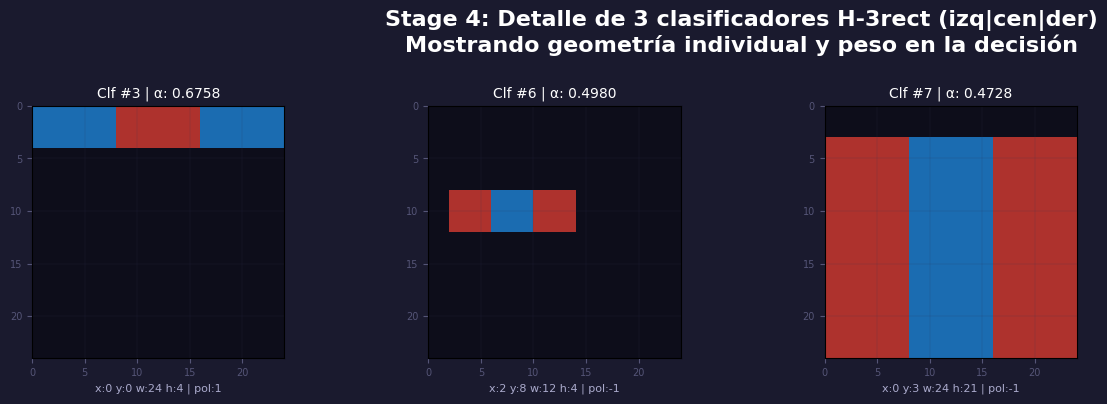

In [14]:
def plot_individual_classifiers(stage_idx, target_ftype):
    """
    Muestra cada clasificador individual de un tipo específico en un stage dado.
    """
    # 1. Obtener datos del stage seleccionado
    if stage_idx >= len(stages):
        print(f"Error: El stage {stage_idx+1} no existe.")
        return
    
    stage = stages[stage_idx]
    clfs = stage['classifiers']
    alphas = stage['alphas']
    feat_list = stage['features_global']
    
    # 2. Filtrar clasificadores por tipo
    indices_filtrados = []
    for i, clf in enumerate(clfs):
        _, _, _, _, ftype = feat_list[clf.feature_index]
        if ftype == target_ftype:
            indices_filtrados.append(i)
            
    n_encontrados = len(indices_filtrados)
    if n_encontrados == 0:
        print(f"No hay clasificadores de tipo {FTYPE_NAMES[target_ftype]} en el Stage {stage_idx+1}")
        return

    # 3. Configurar grid de plots (ej. 4 columnas)
    cols = 4
    rows = (n_encontrados + cols - 1) // cols
    fig = plt.figure(figsize=(cols * 4, rows * 4))
    fig.patch.set_facecolor('#1a1a2e')
    
    plt.suptitle(
        f'Stage {stage_idx + 1}: Detalle de {n_encontrados} clasificadores {FTYPE_NAMES[target_ftype].replace("\n", " ")}\n'
        f'Mostrando geometría individual y peso en la decisión',
        fontsize=16, color='white', fontweight='bold', y=0.98
    )

    for i, idx in enumerate(indices_filtrados):
        ax = fig.add_subplot(rows, cols, i + 1)
        clf = clfs[idx]
        alpha = alphas[idx]
        x, y, w, h, ftype = feat_list[clf.feature_index]
        
        ax.set_facecolor('#0d0d1a')
        ax.set_xlim(0, WINDOW_SIZE)
        ax.set_ylim(WINDOW_SIZE, 0)
        ax.set_aspect('equal')

        # Dibujar la geometría del clasificador
        # Reutilizamos la lógica de rectángulos pero aplicada a este AX
        rect_kwargs = dict(linewidth=1, alpha=0.7)
        sign = clf.polarity # Importante: la polaridad invierte el significado de los colores
        
        # Color base (Azul si positivo, Rojo si negativo según polaridad)
        c_pos = '#2196F3' if sign > 0 else '#F44336'
        c_neg = '#F44336' if sign > 0 else '#2196F3'

        if ftype == 2: # H-3rect (tu ftype favorito)
            tw = w // 3
            # Rectángulos laterales
            ax.add_patch(patches.Rectangle((x, y), tw, h, facecolor=c_pos, **rect_kwargs))
            ax.add_patch(patches.Rectangle((x + 2*tw, y), tw, h, facecolor=c_pos, **rect_kwargs))
            # Rectángulo central
            ax.add_patch(patches.Rectangle((x + tw, y), tw, h, facecolor=c_neg, **rect_kwargs))
        
        # --- (Puedes añadir aquí el resto de ftypes 0, 1, 3, 4 siguiendo la misma lógica si los necesitas) ---
        elif ftype == 0: # H-2rect
            hw = w // 2
            ax.add_patch(patches.Rectangle((x, y), hw, h, facecolor=c_pos, **rect_kwargs))
            ax.add_patch(patches.Rectangle((x+hw, y), hw, h, facecolor=c_neg, **rect_kwargs))
            
        # Info del clasificador
        ax.set_title(f"Clf #{idx} | α: {alpha:.4f}", color='white', fontsize=10)
        ax.set_xlabel(f"x:{int(x)} y:{int(y)} w:{int(w)} h:{int(h)} | pol:{sign}", 
                      color='#aaaacc', fontsize=8)
        
        # Estética de los ejes
        ax.tick_params(colors='#555577', labelsize=7)
        ax.grid(color='#333355', linewidth=0.3, alpha=0.4)

    plt.tight_layout(rect=[0, 0.03, 1, 0.93])
    plt.show()

# ── EJECUCIÓN ────────────────────────────────────────────────
# Elige el Stage (0 a 3) y el ftype (0 a 4)
# Stage 4 en tu código original es el índice 3.
# Ftype 2 es el H-3rect.
plot_individual_classifiers(stage_idx=3, target_ftype=2)

In [1]:
import os
import cv2
import numpy as np

# --- CONFIG ---
image_dir = "dataset/faces"

# --- CARGAR MODELOS (ya vienen con OpenCV) ---
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_eye.xml")

def check_face(img_gray):
    faces = face_cascade.detectMultiScale(img_gray, 1.3, 5)

    if len(faces) == 0:
        return False, "No face"

    for (x, y, w, h) in faces:
        face_roi = img_gray[y:y+h, x:x+w]

        eyes = eye_cascade.detectMultiScale(face_roi)

        if len(eyes) < 2:
            return False, "No 2 eyes"

        # Tomar los 2 ojos más grandes
        eyes = sorted(eyes, key=lambda e: e[2]*e[3], reverse=True)[:2]

        eye_centers = []
        for (ex, ey, ew, eh) in eyes:
            cx = ex + ew/2
            cy = ey + eh/2
            eye_centers.append((cx, cy))

        (x1, y1), (x2, y2) = eye_centers

        # 1. Alineación vertical
        eye_diff_y = abs(y1 - y2)

        # 2. Simetría horizontal
        face_center_x = w / 2
        dist1 = abs(x1 - face_center_x)
        dist2 = abs(x2 - face_center_x)
        symmetry_diff = abs(dist1 - dist2)

        # Umbrales
        aligned = eye_diff_y < 0.1 * h
        symmetric = symmetry_diff < 0.15 * w

        if aligned and symmetric:
            return True, "OK"
        else:
            return False, f"Misaligned (dy={eye_diff_y:.1f}, sym={symmetry_diff:.1f})"

    return False, "Unknown"


# --- LOOP ---
results = []

for filename in os.listdir(image_dir):
    path = os.path.join(image_dir, filename)

    if not filename.lower().endswith((".jpg", ".png", ".jpeg")):
        continue

    img = cv2.imread(path)
    if img is None:
        continue
    img = cv2.resize(img, (96,96))

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ok, msg = check_face(gray)

    status = "✅ OK" if ok else "⚠️ " + msg
    print(f"{filename}: {status}")

    results.append(ok)


# --- RESUMEN ---
total = len(results)
good = sum(results)

print("\n--- RESUMEN ---")
print(f"Total: {total}")
print(f"Buenas: {good}")
print(f"Porcentaje: {100 * good / total:.2f}%")

face_0100.png: ⚠️ No face
face_6151.png: ⚠️ No face
face_8000.png: ⚠️ No face
face_9295.png: ⚠️ No 2 eyes
face_6355.png: ⚠️ No 2 eyes
face_7261.png: ⚠️ No 2 eyes
face_0821.png: ⚠️ No face
face_2295.png: ⚠️ No face
face_8615.png: ⚠️ No face
face_8700.png: ⚠️ No 2 eyes
face_1399.png: ⚠️ No 2 eyes
face_7988.png: ⚠️ No face
face_3704.png: ⚠️ No face
face_0357.png: ⚠️ No face
face_5065.png: ⚠️ No face
face_0115.png: ✅ OK
face_5443.png: ⚠️ No 2 eyes
face_3869.png: ⚠️ No face
face_2105.png: ⚠️ No face
face_1415.png: ⚠️ No face
face_4792.png: ⚠️ No 2 eyes
face_4505.png: ⚠️ No face
face_0935.png: ⚠️ No face
face_4178.png: ⚠️ No face
face_5871.png: ⚠️ No face
face_6529.png: ⚠️ No face
face_7340.png: ✅ OK
face_9879.png: ⚠️ No face
face_6096.png: ⚠️ No face
face_5308.png: ⚠️ No face
face_7385.png: ⚠️ No face
face_9943.png: ⚠️ No face
face_4652.png: ⚠️ No 2 eyes
face_6654.png: ⚠️ No face
face_6289.png: ⚠️ No face
face_5961.png: ⚠️ No 2 eyes
face_2378.png: ⚠️ No 2 eyes
face_3982.png: ⚠️ No face
face